# Train Ticket Sales in India – Data Analysis and Visualization
**Course:** Exploratory Data Analysis and Visualization (EDAV, 22ADC32N) – Course-End Project  
**Dataset:** `train_ticket_sales_india.csv` (8,000 ticket sales, Jan 2023 – Sep 2025)

---
## Introduction
Railway ticket sales data reveal who travels, on which routes, in which class, and how they pay. In this project we analyse a dataset of 8,000 train ticket sales in India using **NumPy, Pandas, Matplotlib and Seaborn**.

## Objectives
1. Inspect the dataset for missing values, duplicates, data types and anomalies, and clean it.
2. Use **NumPy** to compute average, minimum and maximum age and fare for each coach type.
3. Use **Pandas** (`groupby`, `pivot_table`, `crosstab`) to study how coach type, payment mode and passenger age relate to fares and sales.
4. Group sales by source station / route / coach type and compute descriptive statistics.
5. Build bar plots, box plots, histograms, line charts and heatmaps, and state conclusions from them.

## Dataset description
| Column | Meaning |
|---|---|
| Ticket_ID | Unique ticket number |
| Sale_Date | Date on which the ticket was sold |
| Source_Station / Destination_Station | Origin and destination of the journey |
| Passenger_Age | Age of the passenger (years) |
| Coach_Type | General, Sleeper or AC |
| Ticket_Price | Fare paid (Rs.) |
| Payment_Mode | Cash, Card, UPI or NetBanking |

**Workflow:** Data Loading → Data Cleaning → Analysis → Visualization → Conclusion.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Importing Required Libraries
**Concept:** NumPy handles numeric array operations, Pandas handles tabular data, and Matplotlib/Seaborn draw the charts.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
print("Libraries loaded successfully")

Libraries loaded successfully


## 2. Loading the Dataset
**Concept:** Read the CSV into a Pandas DataFrame. Keep `train_ticket_sales_india.csv` in the **same folder** as this notebook.  
*If the file is somewhere else, change the line to `df = pd.read_csv(r"full\path\to\train_ticket_sales_india.csv")`.*

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/train_ticket_sales_india (2).csv")
df.head()

,Ticket_ID,Sale_Date,Source_Station,Destination_Station,Passenger_Age,Coach_Type,Ticket_Price,Payment_Mode
0,1,2023-01-01,SBC,Delhi,24,Sleeper,1065,Cash
1,2,2023-01-01,Mumbai,Chennai,46,General,338,Cash
2,3,2023-01-01,SBC,Mumbai,76,General,420,UPI
3,4,2023-01-01,BCT,HWH,38,Sleeper,872,UPI
4,5,2023-01-01,Delhi,Delhi,54,AC,1653,UPI


## 3. Understanding the Dataset
**Concept:** Check the size, column names, data types and summary statistics before any analysis.

In [ ]:
print("Shape (rows, columns):", df.shape)
print()
df.info()

Shape (rows, columns): (8000, 8)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Ticket_ID            8000 non-null   int64 
 1   Sale_Date            8000 non-null   object
 2   Source_Station       8000 non-null   object
 3   Destination_Station  8000 non-null   object
 4   Passenger_Age        8000 non-null   int64 
 5   Coach_Type           8000 non-null   object
 6   Ticket_Price         8000 non-null   int64 
 7   Payment_Mode         8000 non-null   object
dtypes: int64(3), object(5)
memory usage: 500.1+ KB


In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Ticket_ID,8000.0,NaN,NaN,NaN,4000.5,2309.54541,1.0,2000.75,4000.5,6000.25,8000.0
Sale_Date,8000,999,2023-11-29,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Source_Station,8000,10,Gorakhpur,832,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Destination_Station,8000,10,SBC,884,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Passenger_Age,8000.0,NaN,NaN,NaN,42.667,22.009814,5.0,24.0,43.0,62.0,80.0
Coach_Type,8000,3,Sleeper,4022,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket_Price,8000.0,NaN,NaN,NaN,967.876125,611.669741,200.0,458.0,844.0,1151.0,2500.0
Payment_Mode,8000,4,UPI,2432,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Insight:** The dataset has **8,000 rows and 8 columns** with no null values. `Sale_Date` is stored as text and must be converted to a date. Ages range from 5 to 80 years and fares from Rs. 200 to Rs. 2,500. The station columns have 10 labels each.

## 4. Data Cleaning and Preprocessing  *(Handling missing values, duplicates and anomalies)*
**Concept:** Prepare a clean dataset for statistical and visual analysis. We first audit the data for missing values, duplicates, invalid values and inconsistent labels.

In [ ]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows            :", df.duplicated().sum())
print("Duplicate Ticket_IDs      :", df["Ticket_ID"].duplicated().sum())
print("Age range                 :", df["Passenger_Age"].min(), "to", df["Passenger_Age"].max())
print("Tickets with price <= 0   :", (df["Ticket_Price"] <= 0).sum())
print("\nStation labels in Source_Station     :", sorted(df["Source_Station"].unique()))
print("Station labels in Destination_Station:", sorted(df["Destination_Station"].unique()))
print("Coach types :", sorted(df["Coach_Type"].unique()))
print("Payment modes:", sorted(df["Payment_Mode"].unique()))

Missing values per column:
Ticket_ID              0
Sale_Date              0
Source_Station         0
Destination_Station    0
Passenger_Age          0
Coach_Type             0
Ticket_Price           0
Payment_Mode           0
dtype: int64

Duplicate rows            : 0
Duplicate Ticket_IDs      : 0
Age range                 : 5 to 80
Tickets with price <= 0   : 0

Station labels in Source_Station     : ['BCT', 'Chennai', 'Delhi', 'Gorakhpur', 'HWH', 'Jaipur', 'MAS', 'Mumbai', 'NDLS', 'SBC']
Station labels in Destination_Station: ['BCT', 'Chennai', 'Delhi', 'Gorakhpur', 'HWH', 'Jaipur', 'MAS', 'Mumbai', 'NDLS', 'SBC']
Coach types : ['AC', 'General', 'Sleeper']
Payment modes: ['Card', 'Cash', 'NetBanking', 'UPI']


**Insight:** There are **no missing values, no duplicate rows and no duplicate ticket IDs**; ages and prices are all valid. However, the station columns mix **railway codes** (NDLS, BCT, MAS, SBC, HWH) with **city names** (Delhi, Mumbai, Chennai …). The same city therefore appears under two labels, which would split its counts in any group-wise analysis.

**Cleaning steps applied below**
1. Map station codes to city names (assumption based on standard railway codes: NDLS → Delhi, BCT → Mumbai, MAS → Chennai, SBC → Bengaluru, HWH → Kolkata).
2. Convert `Sale_Date` to datetime and derive Year, Month and Weekday.
3. Remove tickets where source and destination are the same city (not a valid journey).
4. Create an `Age_Group` column and a `Route` column.

In [ ]:
clean = df.copy()

# 1. Standardise station names: railway codes -> city names
station_map = {"NDLS": "Delhi", "BCT": "Mumbai", "MAS": "Chennai",
               "SBC": "Bengaluru", "HWH": "Kolkata"}
clean["Source_Station"] = clean["Source_Station"].replace(station_map)
clean["Destination_Station"] = clean["Destination_Station"].replace(station_map)
print("Stations after standardising:", sorted(clean["Source_Station"].unique()))

# 2. Convert Sale_Date to datetime and derive time features
clean["Sale_Date"] = pd.to_datetime(clean["Sale_Date"])
clean["Year"] = clean["Sale_Date"].dt.year
clean["Month"] = clean["Sale_Date"].dt.to_period("M").astype(str)
clean["Weekday"] = clean["Sale_Date"].dt.day_name()

# 3. Remove impossible journeys (source and destination are the same city)
same = clean["Source_Station"] == clean["Destination_Station"]
print("\nRows where source == destination:", same.sum())
clean = clean[~same].reset_index(drop=True)

# 4. Create age groups for demographic analysis
clean["Age_Group"] = pd.cut(clean["Passenger_Age"], bins=[0, 17, 35, 59, 120],
                            labels=["Child/Teen (<=17)", "Young Adult (18-35)",
                                    "Middle Age (36-59)", "Senior (60+)"])
# 5. Route column
clean["Route"] = clean["Source_Station"] + " -> " + clean["Destination_Station"]

print("\nRows before cleaning:", len(df), "| after cleaning:", len(clean))
print("Missing values remaining:", clean.isnull().sum().sum())
clean.head()

Stations after standardising: ['Bengaluru', 'Chennai', 'Delhi', 'Gorakhpur', 'Jaipur', 'Kolkata', 'Mumbai']

Rows where source == destination: 1262

Rows before cleaning: 8000 | after cleaning: 6738
Missing values remaining: 0


,Ticket_ID,Sale_Date,Source_Station,Destination_Station,Passenger_Age,Coach_Type,Ticket_Price,Payment_Mode,Year,Month,Weekday,Age_Group,Route
0,1,2023-01-01,Bengaluru,Delhi,24,Sleeper,1065,Cash,2023,2023-01,Sunday,Young Adult (18-35),Bengaluru -> Delhi
1,2,2023-01-01,Mumbai,Chennai,46,General,338,Cash,2023,2023-01,Sunday,Middle Age (36-59),Mumbai -> Chennai
2,3,2023-01-01,Bengaluru,Mumbai,76,General,420,UPI,2023,2023-01,Sunday,Senior (60+),Bengaluru -> Mumbai
3,4,2023-01-01,Mumbai,Kolkata,38,Sleeper,872,UPI,2023,2023-01,Sunday,Middle Age (36-59),Mumbai -> Kolkata
4,6,2023-01-01,Mumbai,Bengaluru,15,AC,1748,Cash,2023,2023-01,Sunday,Child/Teen (<=17),Mumbai -> Bengaluru


**Insight:** After standardising the labels, the 10 station labels reduce to **7 cities**. **1,262 rows** had the same source and destination and were removed, leaving **6,738 valid tickets** with no missing values.

### 4.1 Outlier Check
**Concept:** Identify unusual fares using the 1.5 × IQR rule. Fares differ strongly by coach, so the rule is applied within each coach type.

In [ ]:
# Outlier check using the IQR rule, separately for each coach type
rows = []
for coach, g in clean.groupby("Coach_Type"):
    q1, q3 = g["Ticket_Price"].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((g["Ticket_Price"] < low) | (g["Ticket_Price"] > high)).sum()
    rows.append([coach, g["Ticket_Price"].min(), g["Ticket_Price"].max(), low, high, n_out])
pd.DataFrame(rows, columns=["Coach_Type", "Min", "Max", "Lower fence", "Upper fence", "Outliers"])

,Coach_Type,Min,Max,Lower fence,Upper fence,Outliers
0,AC,1500,2500,986.5,3062.5,0
1,General,200,500,52.5,648.5,0
2,Sleeper,600,1200,285.5,1513.5,0


**Insight:** No outliers are found within any coach type. Fares fall in clear, non-overlapping bands: General Rs. 200–500, Sleeper Rs. 600–1,200 and AC Rs. 1,500–2,500. The high fares seen in the overall data are simply AC tickets, not errors, so no fare values were removed.

## 5. Q1 – NumPy: Average, Minimum and Maximum Age and Fare by Coach Type
**Concept:** Use NumPy boolean masks and array functions (`mean`, `min`, `max`, `corrcoef`) to compute statistics for each coach type, similar to computing age statistics by survival status.  
**Steps:** convert columns to NumPy arrays → build a mask per coach → apply array functions.

In [ ]:

age = clean["Passenger_Age"].to_numpy()
price = clean["Ticket_Price"].to_numpy()
coach = clean["Coach_Type"].to_numpy()

print(f"{'Coach':<10}{'Tickets':>8}{'Avg age':>9}{'Min age':>9}{'Max age':>9}"
      f"{'Avg price':>11}{'Min price':>11}{'Max price':>11}")
for c in ["General", "Sleeper", "AC"]:
    mask = coach == c
    print(f"{c:<10}{mask.sum():>8}{age[mask].mean():>9.2f}{age[mask].min():>9}{age[mask].max():>9}"
          f"{price[mask].mean():>11.2f}{price[mask].min():>11}{price[mask].max():>11}")

print("\nOverall average age   :", round(age.mean(), 2))
print("Overall average price :", round(price.mean(), 2))
print("Correlation (age, price):", round(np.corrcoef(age, price)[0, 1], 4))

Coach      Tickets  Avg age  Min age  Max age  Avg price  Min price  Max price
General       1965    42.78        5       80     349.82        200        500
Sleeper       3380    42.59        5       80     897.84        600       1200
AC            1393    42.63        5       80    2016.30       1500       2500

Overall average age   : 42.66
Overall average price : 969.25
Correlation (age, price): -0.0005


**Conclusion / Insight:** The average passenger age is almost identical in every coach (about 42.6–42.8 years) and every coach carries passengers from 5 to 80 years. Average fares differ sharply: about **Rs. 350 (General), Rs. 898 (Sleeper) and Rs. 2,016 (AC)**. The age–fare correlation is about **−0.0005**, i.e. essentially zero: fare is determined by the coach class, not by passenger age.

## 6. Q2 – Pandas: Influence of Coach Type, Payment Mode and Age on Sales
**Concept:** Use `crosstab`, `groupby` with aggregation and `pivot_table` to see how coach type relates to payment mode, revenue and age group.

In [ ]:

pd.crosstab(clean["Payment_Mode"], clean["Coach_Type"], normalize="index").mul(100).round(1)

Coach_Type,AC,General,Sleeper
Payment_Mode,,,
Card,21.3,27.5,51.2
Cash,20.5,30.2,49.3
NetBanking,20.9,30.2,48.9
UPI,20.2,29.0,50.8


**Insight:** In every payment mode, Sleeper makes up about half of the tickets (49–51%), General about 28–30% and AC about 20–21%. Passengers do not choose a payment mode according to the coach they travel in.

In [ ]:

coach_summary = clean.groupby("Coach_Type").agg(
    Tickets=("Ticket_ID", "count"),
    Avg_Price=("Ticket_Price", "mean"),
    Total_Revenue=("Ticket_Price", "sum"),
    Avg_Age=("Passenger_Age", "mean"))
coach_summary["Revenue_Share_%"] = (coach_summary["Total_Revenue"] / coach_summary["Total_Revenue"].sum() * 100)
coach_summary.round(2).sort_values("Total_Revenue", ascending=False)

,Tickets,Avg_Price,Total_Revenue,Avg_Age,Revenue_Share_%
Coach_Type,,,,,
Sleeper,3380,897.84,3034700,42.59,46.47
AC,1393,2016.30,2808708,42.63,43.01
General,1965,349.82,687398,42.78,10.53


**Insight:** **Sleeper** brings the most revenue (Rs. 30.3 lakh, 46.5%), followed closely by **AC** (Rs. 28.1 lakh, 43.0%) even though AC has fewer tickets (1,393 vs 3,380). **General** has 29% of tickets but only 10.5% of revenue.

In [ ]:

clean.pivot_table(values="Ticket_Price", index="Age_Group", columns="Coach_Type", aggfunc="mean").round(1)

Coach_Type,AC,General,Sleeper
Age_Group,,,
Child/Teen (<=17),2018.6,349.1,899.0
Young Adult (18-35),2010.7,346.7,904.1
Middle Age (36-59),2011.5,352.4,887.8
Senior (60+),2025.1,349.9,902.5


**Insight:** The average fare within a coach is practically the same for all age groups (e.g. AC ≈ Rs. 2,010–2,025). No age-based concession or premium is visible in this data.

## 7. Q3 – Group-wise Descriptive Statistics by Station, Route and Payment Mode
**Concept:** Use `groupby(['Source_Station','Coach_Type'])` and aggregation functions (`count`, `mean`, `sum`) to summarise sales, as done for embarkation port and survival in the reference project.

In [ ]:

src = clean.groupby(["Source_Station", "Coach_Type"]).agg(
    Tickets=("Ticket_ID", "count"), Avg_Price=("Ticket_Price", "mean")).round(2)
src.head(12)

Tickets  Avg_Price
Source_Station Coach_Type                    
Bengaluru      AC              151    2005.42
               General         201     345.95
               Sleeper         349     895.87
Chennai        AC              262    2052.24
               General         403     346.18
               Sleeper         631     909.07
Delhi          AC              274    2012.89
               General         367     348.56
               Sleeper         654     898.85
Gorakhpur      AC              149    1997.62
               General         204     352.35
               Sleeper         401     894.45

In [ ]:

station = clean.groupby("Source_Station").agg(
    Tickets=("Ticket_ID", "count"),
    Avg_Price=("Ticket_Price", "mean"),
    Revenue=("Ticket_Price", "sum")).round(2)
station.sort_values("Revenue", ascending=False)

,Tickets,Avg_Price,Revenue
Source_Station,,,
Delhi,1295,978.61,1267300
Chennai,1296,965.14,1250819
Mumbai,1288,943.52,1215258
Gorakhpur,754,965.78,728201
Kolkata,710,999.76,709827
Bengaluru,701,977.20,685014
Jaipur,694,971.74,674387


**Insight:** **Delhi, Chennai and Mumbai** each sell about 1,290 tickets (≈ Rs. 12–12.7 lakh), almost double the other stations (≈ 700–750 tickets each). Average fares per station lie in a narrow range (≈ Rs. 944–1,000).  
*Note:* these three cities appear under two labels (code and name) in the raw data, so their larger counts should be read with that in mind; the lower-volume stations had a single label.

In [ ]:
# Ten busiest routes
route = clean.groupby("Route").agg(Tickets=("Ticket_ID", "count"),
                                   Avg_Price=("Ticket_Price", "mean"),
                                   Revenue=("Ticket_Price", "sum")).round(2)
route.sort_values("Tickets", ascending=False).head(10)

,Tickets,Avg_Price,Revenue
Route,,,
Mumbai -> Chennai,337,939.02,316451
Delhi -> Chennai,321,967.22,310477
Chennai -> Delhi,320,931.96,298227
Mumbai -> Delhi,317,937.68,297244
Chennai -> Mumbai,316,960.57,303540
Delhi -> Mumbai,314,1033.19,324421
Chennai -> Bengaluru,189,1009.90,190871
Delhi -> Bengaluru,188,959.61,180406
Delhi -> Gorakhpur,171,1036.05,177165


**Insight:** The busiest routes are all between the three big cities: **Mumbai → Chennai (337 tickets)**, Delhi → Chennai (321), Chennai → Delhi (320) and Mumbai → Delhi (317).

In [ ]:
# Payment mode summary
pay = clean.groupby("Payment_Mode").agg(Tickets=("Ticket_ID", "count"),
                                        Avg_Price=("Ticket_Price", "mean"),
                                        Revenue=("Ticket_Price", "sum")).round(2)
pay["Share_%"] = (pay["Tickets"] / pay["Tickets"].sum() * 100).round(1)
pay.sort_values("Tickets", ascending=False)

,Tickets,Avg_Price,Revenue,Share_%
Payment_Mode,,,,
UPI,2056,966.56,1987239,30.5
Card,1715,989.46,1696926,25.5
Cash,1684,951.92,1603040,25.0
NetBanking,1283,969.29,1243601,19.0


**Insight:** **UPI** is the most used payment mode (30.5% of tickets), followed by Card (25.5%), Cash (25.0%) and NetBanking (19.0%). Digital modes together account for about 75% of tickets. Average fares are similar across payment modes (≈ Rs. 950–990).

## 8. Q4 – Data Visualization
**Concept:** Present the results visually using bar plots, box plots, histograms, line charts and heatmaps with proper titles, axis labels and legends.

### 8.1 Bar plots – fares, payment modes and coach choice by age group

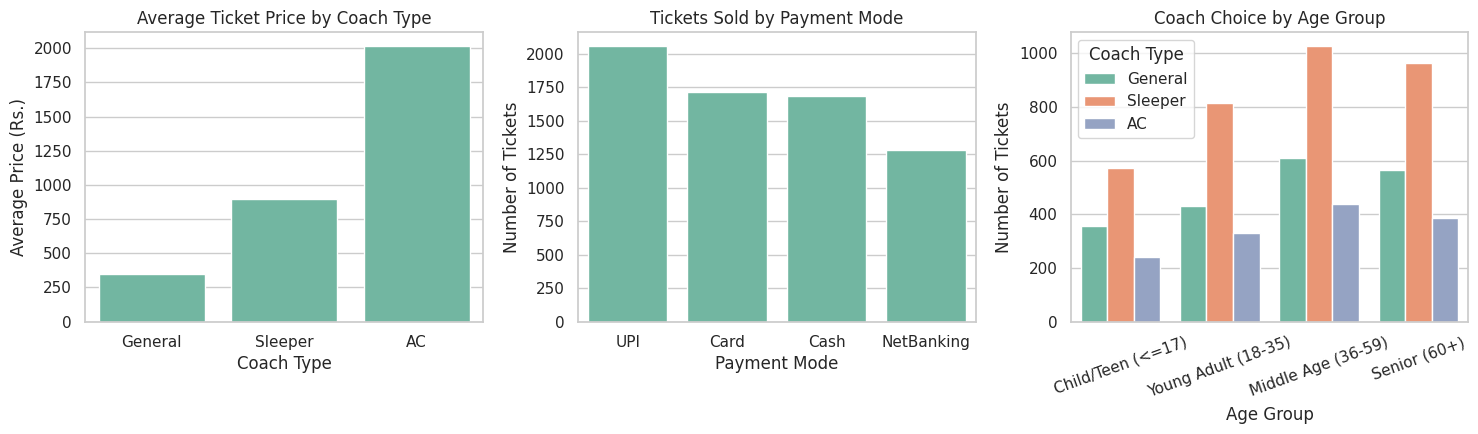

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

order = ["General", "Sleeper", "AC"]
sns.barplot(data=clean, x="Coach_Type", y="Ticket_Price", order=order, estimator=np.mean,
            errorbar=None, ax=axes[0])
axes[0].set_title("Average Ticket Price by Coach Type")
axes[0].set_xlabel("Coach Type"); axes[0].set_ylabel("Average Price (Rs.)")

sns.countplot(data=clean, x="Payment_Mode", order=clean["Payment_Mode"].value_counts().index, ax=axes[1])
axes[1].set_title("Tickets Sold by Payment Mode")
axes[1].set_xlabel("Payment Mode"); axes[1].set_ylabel("Number of Tickets")

sns.countplot(data=clean, x="Age_Group", hue="Coach_Type", hue_order=order, ax=axes[2])
axes[2].set_title("Coach Choice by Age Group")
axes[2].set_xlabel("Age Group"); axes[2].set_ylabel("Number of Tickets")
axes[2].tick_params(axis="x", rotation=20)
axes[2].legend(title="Coach Type")

plt.tight_layout()
plt.show()

**Insight:** Average fare rises steeply from General to Sleeper to AC. UPI leads the payment modes. In every age group Sleeper is the most chosen coach and AC the least, so the coach mix is similar across ages.

### 8.2 Box plot and histogram – fare and age distributions

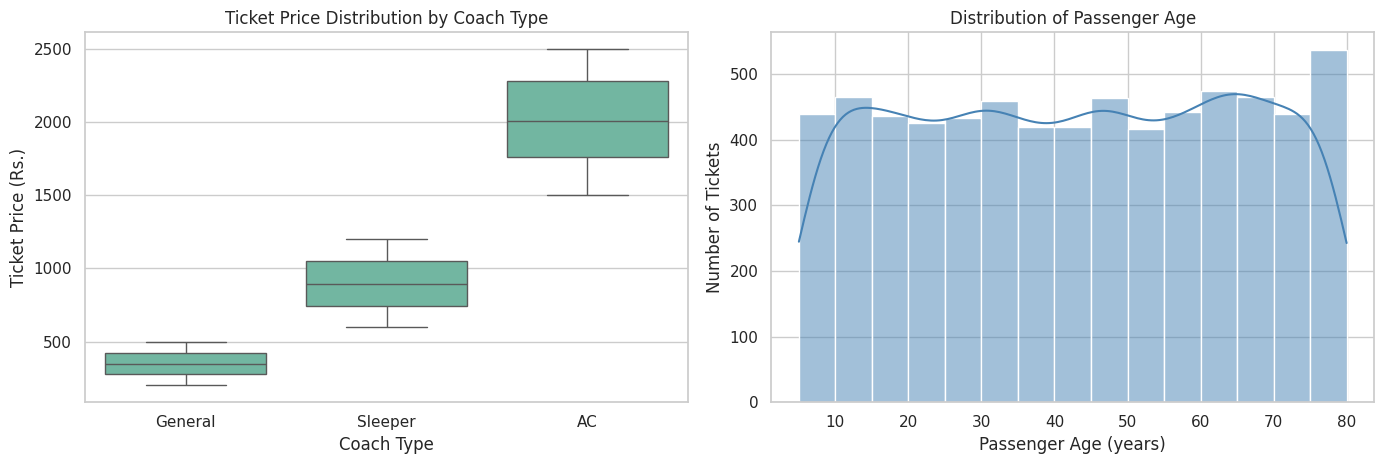

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

sns.boxplot(data=clean, x="Coach_Type", y="Ticket_Price", order=["General", "Sleeper", "AC"], ax=axes[0])
axes[0].set_title("Ticket Price Distribution by Coach Type")
axes[0].set_xlabel("Coach Type"); axes[0].set_ylabel("Ticket Price (Rs.)")

sns.histplot(clean["Passenger_Age"], bins=15, kde=True, ax=axes[1], color="steelblue")
axes[1].set_title("Distribution of Passenger Age")
axes[1].set_xlabel("Passenger Age (years)"); axes[1].set_ylabel("Number of Tickets")

plt.tight_layout()
plt.show()

**Insight:** The box plot confirms three separate fare bands with no overlap and no outliers. Passenger age is spread almost evenly between 5 and 80 years, with no dominant age group.

### 8.3 Heatmaps – routes and coach types

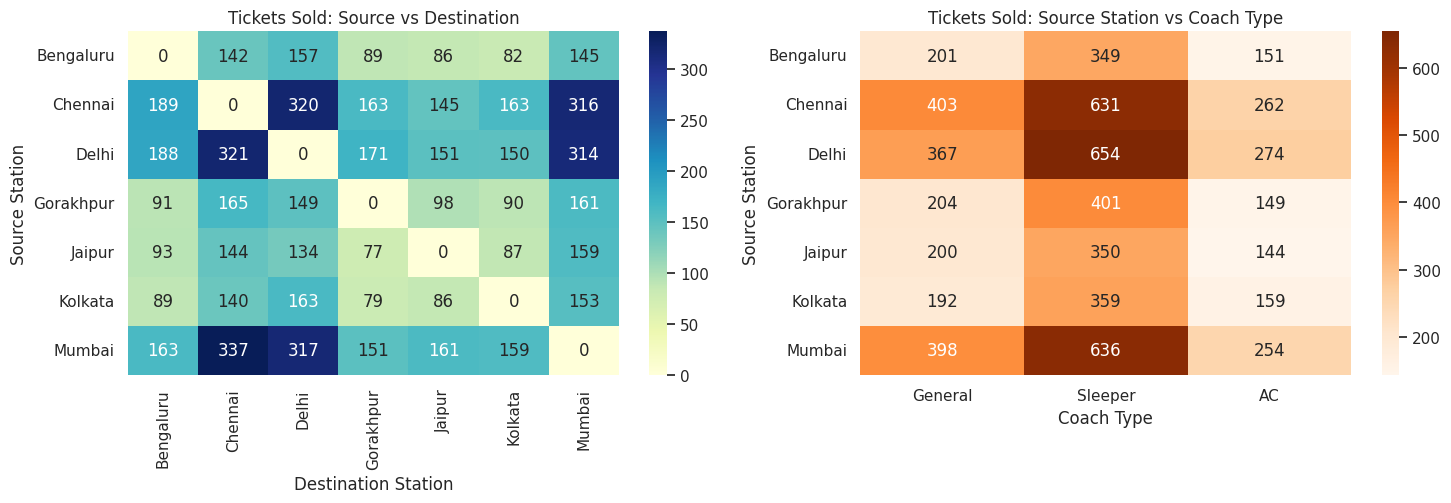

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

od = pd.crosstab(clean["Source_Station"], clean["Destination_Station"])
sns.heatmap(od, annot=True, fmt="d", cmap="YlGnBu", ax=axes[0])
axes[0].set_title("Tickets Sold: Source vs Destination")
axes[0].set_xlabel("Destination Station"); axes[0].set_ylabel("Source Station")

sc = clean.pivot_table(index="Source_Station", columns="Coach_Type", values="Ticket_ID",
                       aggfunc="count")[["General", "Sleeper", "AC"]]
sns.heatmap(sc, annot=True, fmt="d", cmap="Oranges", ax=axes[1])
axes[1].set_title("Tickets Sold: Source Station vs Coach Type")
axes[1].set_xlabel("Coach Type"); axes[1].set_ylabel("Source Station")

plt.tight_layout()
plt.show()

**Insight:** The darkest cells in the left heatmap are the Mumbai–Chennai–Delhi corridors. The right heatmap shows Sleeper is the leading coach at every source station and that Delhi, Chennai and Mumbai have the highest volumes in each coach type.

### 8.4 Monthly trend and payment mode by coach type

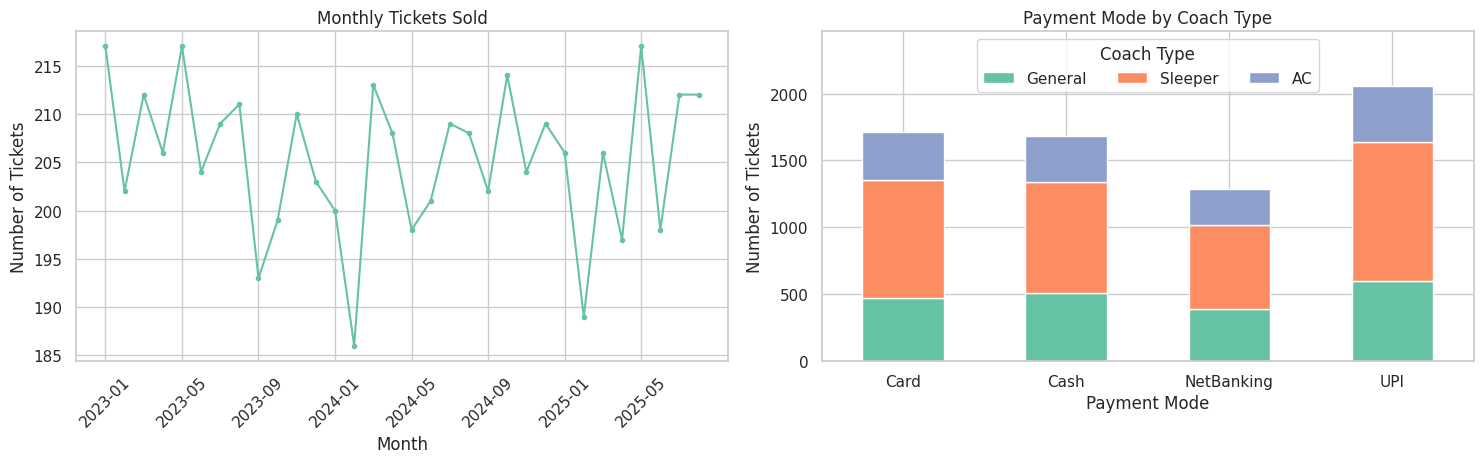

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# The last month (Sep-2025) is incomplete (data ends on 25 Sep), so it is left out of the trend line
monthly = clean[clean["Month"] < "2025-09"].groupby("Month").agg(Tickets=("Ticket_ID", "count"))
axes[0].plot(monthly.index, monthly["Tickets"], marker="o", markersize=3)
axes[0].set_title("Monthly Tickets Sold")
axes[0].set_xlabel("Month"); axes[0].set_ylabel("Number of Tickets")
axes[0].set_xticks(range(0, len(monthly), 4))
axes[0].set_xticklabels(monthly.index[::4], rotation=45)

pm = clean.pivot_table(index="Payment_Mode", columns="Coach_Type", values="Ticket_ID",
                       aggfunc="count")[["General", "Sleeper", "AC"]]
pm.plot(kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Payment Mode by Coach Type")
axes[1].set_xlabel("Payment Mode"); axes[1].set_ylabel("Number of Tickets")
axes[1].tick_params(axis="x", rotation=0)
axes[1].set_ylim(0, pm.sum(axis=1).max() * 1.2)
axes[1].legend(title="Coach Type", ncol=3, loc="upper center")

plt.tight_layout()
plt.show()

**Insight:** Monthly ticket sales stay in a stable band of roughly **186–217 tickets** per month from January 2023 to August 2025, with no clear upward or downward trend. September 2025 is left out because the data ends on 25 September. The stacked bars show the same coach mix inside every payment mode.

## 9. Key Findings and Summary Statistics

In [ ]:
print("Total tickets analysed :", len(clean))
print("Total revenue (Rs.)    :", clean["Ticket_Price"].sum())
print("Average ticket price   :", round(clean["Ticket_Price"].mean(), 2))
print("Date range             :", clean["Sale_Date"].min().date(), "to", clean["Sale_Date"].max().date())
print("Most used payment mode :", clean["Payment_Mode"].mode()[0])
print("Busiest route          :", clean["Route"].value_counts().idxmax())
print("Top revenue coach      :", clean.groupby("Coach_Type")["Ticket_Price"].sum().idxmax())

Total tickets analysed : 6738
Total revenue (Rs.)    : 6530806
Average ticket price   : 969.25
Date range             : 2023-01-01 to 2025-09-25
Most used payment mode : UPI
Busiest route          : Mumbai -> Chennai
Top revenue coach      : Sleeper


## 10. Conclusion
- The data were clean in terms of missing values and duplicates, but needed **label standardisation** (station codes vs city names) and removal of **1,262 same-city journeys**; **6,738 tickets** were analysed.
- **Coach type is the only driver of fare**: General ≈ Rs. 350, Sleeper ≈ Rs. 898, AC ≈ Rs. 2,016. Passenger age and payment mode have no visible effect on the fare.
- **Sleeper** is the most used coach (about 50% of tickets) and earns the most revenue (46.5%); **AC** earns 43.0% from just 20.7% of tickets, while **General** earns only 10.5%.
- **UPI** is the most popular payment mode (30.5%), and digital payments make up about three quarters of the sales.
- The busiest corridors are among **Mumbai, Delhi and Chennai**, and monthly sales remained steady across the period.

**Limitations:** the data contain only ticket-level fields (no distance, travel date or train number), so fare differences cannot be explained beyond coach class; the code-to-city mapping is an assumption based on standard railway codes.

**Reproducibility:** run the cells from top to bottom with `train_ticket_sales_india.csv` in the same folder; no random numbers are used, so the results are identical on every run.